In [1]:
import os
import csv
import math
from pathlib import Path
from datetime import datetime
from PIL import Image
import nibabel as nib

import numpy as np
import torch
import yaml
import matplotlib.pyplot as plt
from tqdm import tqdm
from torchvision.transforms import Normalize

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

ROOT_DIR = Path("/home/locolinux2/U24_synthesis")
if str(ROOT_DIR) not in os.sys.path:
    os.sys.path.insert(0, str(ROOT_DIR))

from models import get_model

SEED = 42
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
SYN_ROOT = Path("/mnt/d/Datasets/EMBED/EMBED_clean_256x256/train/synthetic_guide5.0")
REAL_ROOT = Path("/mnt/d/Datasets/EMBED/EMBED_clean_256x256/train/original")
EXPERIMENT_ROOT = ROOT_DIR / "experiments"

ORACLE_DIR = "091_EMBED_binary_256x256_holdout_convnext_tiny_Oracle_seed44_Augsgeometric_real1.0_syn0.0"
ORACLE_CKPT = EXPERIMENT_ROOT / ORACLE_DIR / "last.pt"

CATEGORIES = ["benign", "malignant"]
TOP_K = 8
BOTTOM_K = 8

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

run_dir = Path("./outputs") / f"gradcam_synthetic_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
run_dir.mkdir(parents=True, exist_ok=True)
run_dir

PosixPath('outputs/gradcam_synthetic_20260422_113512')

In [2]:
IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}


def list_synthetic_files(root: Path, class_name: str):
    class_dir = root / class_name
    files = []
    for p in class_dir.rglob("*"):
        if not p.is_file():
            continue
        suf = "".join(p.suffixes).lower()
        if suf.endswith(".nii.gz") or p.suffix.lower() in IMG_EXTS:
            files.append(p)
    return sorted(files)

def list_case_files(root: Path, class_name: str):
    class_dir = root / class_name
    files = []
    for p in class_dir.rglob("*"):
        if not p.is_file():
            continue
        suf = "".join(p.suffixes).lower()
        if suf.endswith(".nii.gz") or p.suffix.lower() in IMG_EXTS:
            files.append(p)
    return sorted(files)

def load_image_as_tensor(path: Path):
    suffix = "".join(path.suffixes).lower()

    if suffix.endswith(".nii.gz") or suffix.endswith(".nii"):
        arr = nib.load(str(path)).get_fdata()
        arr = np.squeeze(arr)

        # If 3D, take middle slice
        if arr.ndim == 3:
            arr = arr[:, :, arr.shape[2] // 2]
        elif arr.ndim != 2:
            raise ValueError(f"Unsupported NIfTI shape for {path}: {arr.shape}")

        arr = arr.astype(np.float32)
    else:
        arr = np.array(Image.open(path).convert("L"), dtype=np.float32)

    # same normalization style as before
    arr = (arr - arr.mean()) / (arr.std() + 1e-8)
    arr = arr - arr.min()
    arr = arr / (arr.max() + 1e-8)

    x = torch.from_numpy(arr).unsqueeze(0)  # 1 x H x W
    return arr, x

def make_overlay(img01, cam_mask, alpha=0.45):
    rgb = np.repeat(img01[..., None], 3, axis=2)
    heat = plt.get_cmap("jet")(cam_mask)[..., :3]
    return np.clip((1 - alpha) * rgb + alpha * heat, 0, 1)

def show_grid(records, title, ncols=4):
    n = len(records)
    if n == 0:
        print("No records to show.")
        return
    ncols = min(ncols, n)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows))
    axes = np.array(axes).reshape(-1)

    for ax in axes[n:]:
        ax.axis("off")

    for i, rec in enumerate(records):
        ax = axes[i]
        ax.imshow(rec["overlay"])
        ax.axis("off")
        ax.set_title(
            f"{rec['path'].name}\n"
            f"true={rec['true_label']} pred={rec['pred_label']}\n"
            f"p(true)={rec['true_prob']:.3f}",
            fontsize=8,
        )

    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    plt.show()

In [3]:
num_classes = 2

oracle = get_model("convnext_tiny", num_classes=len(CATEGORIES), pretrained=False)
ckpt = torch.load(ORACLE_CKPT, map_location="cpu", weights_only=False)
oracle.load_state_dict(ckpt["model_state"])
oracle = oracle.float().to(DEVICE).eval()

oracle_norm = Normalize(mean=[0.5], std=[0.5])
target_layer = oracle.backbone.features[-1]
cam = GradCAM(model=oracle, target_layers=[target_layer])


print("Loaded oracle on", DEVICE)
print("Target layer:", target_layer)

Loaded oracle on cuda:0
Target layer: Sequential(
  (0): CNBlock(
    (block): Sequential(
      (0): Conv2d(768, 768, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=768)
      (1): Permute()
      (2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (3): Linear(in_features=768, out_features=3072, bias=True)
      (4): GELU(approximate='none')
      (5): Linear(in_features=3072, out_features=768, bias=True)
      (6): Permute()
    )
    (stochastic_depth): StochasticDepth(p=0.08823529411764706, mode=row)
  )
  (1): CNBlock(
    (block): Sequential(
      (0): Conv2d(768, 768, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=768)
      (1): Permute()
      (2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (3): Linear(in_features=768, out_features=3072, bias=True)
      (4): GELU(approximate='none')
      (5): Linear(in_features=3072, out_features=768, bias=True)
      (6): Permute()
    )
    (stochastic_depth): StochasticDepth(p=0.0941176

In [4]:
import random

MAX_PER_CLASS = 200
rng = random.Random(SEED)

all_items = []

for source_name, root in [("synthetic", SYN_ROOT), ("original", REAL_ROOT)]:
    for cls_idx, cls_name in enumerate(CATEGORIES):
        files = list_case_files(root, cls_name)
        print(source_name, cls_name, len(files))

        if len(files) > MAX_PER_CLASS:
            files = rng.sample(files, MAX_PER_CLASS)

        for p in files:
            all_items.append((p, cls_idx, cls_name, source_name))

print("Total selected:", len(all_items))

scored = []
for path, true_id, true_label, source_name in tqdm(all_items):
    try:
        img01, x = load_image_as_tensor(path)
        with torch.no_grad():
            inp = oracle_norm(x.unsqueeze(0).to(DEVICE)).float()
            logits = oracle(inp)
            probs = torch.softmax(logits, dim=1).squeeze(0).cpu().numpy()
            pred_id = int(np.argmax(probs))

        scored.append({
            "path": path,
            "source": source_name,
            "true_id": true_id,
            "true_label": true_label,
            "pred_id": pred_id,
            "pred_label": CATEGORIES[pred_id],
            "true_prob": float(probs[true_id]),
            "pred_prob": float(probs[pred_id]),
            "img01": img01,
            "x": x,
        })
    except Exception as e:
        print("Skipping", path, e)

len(scored)

len(scored)

synthetic benign 3444
synthetic malignant 1148
original benign 3444
original malignant 1148
Total selected: 800


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 800/800 [01:22<00:00,  9.68it/s]


800

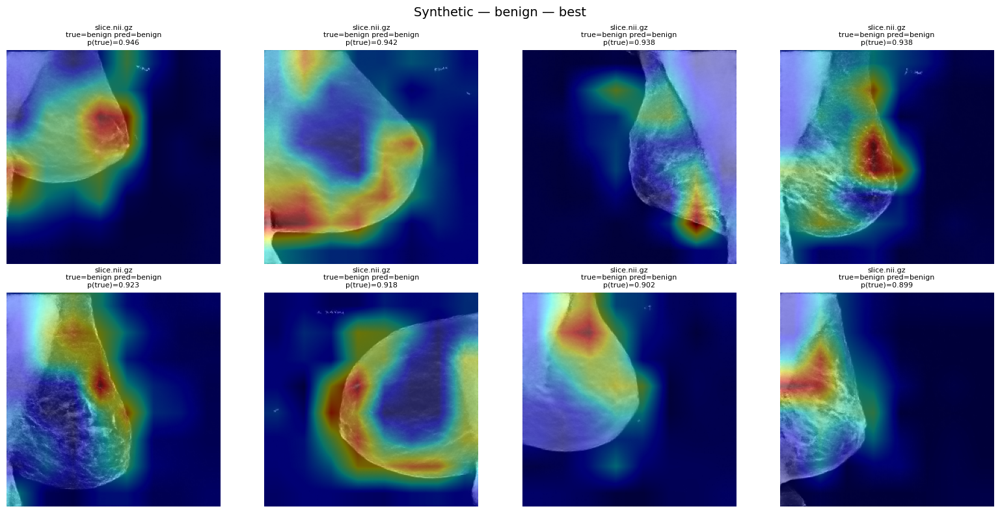

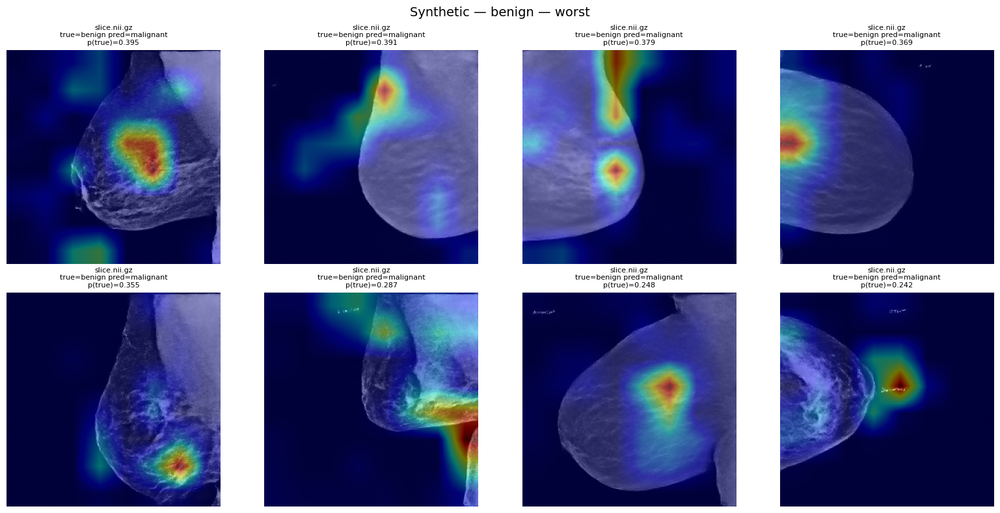

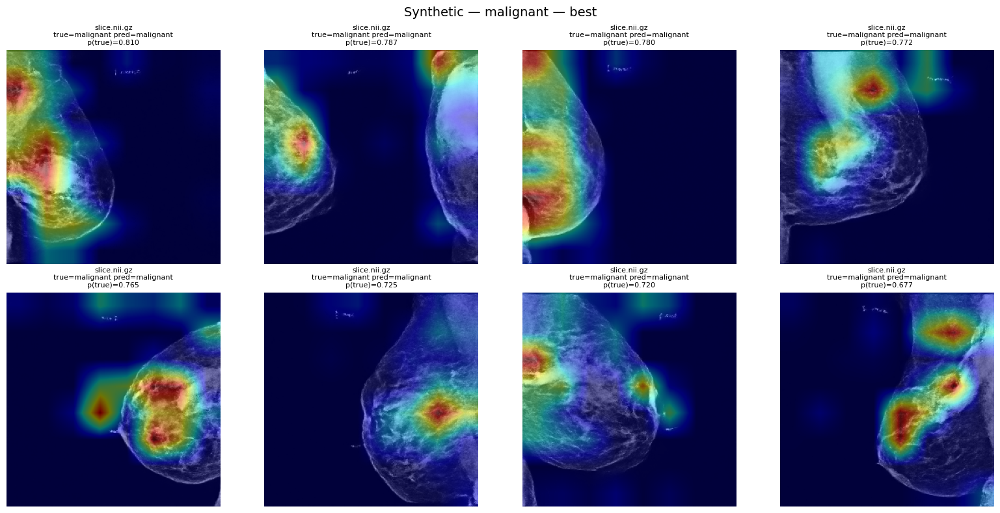

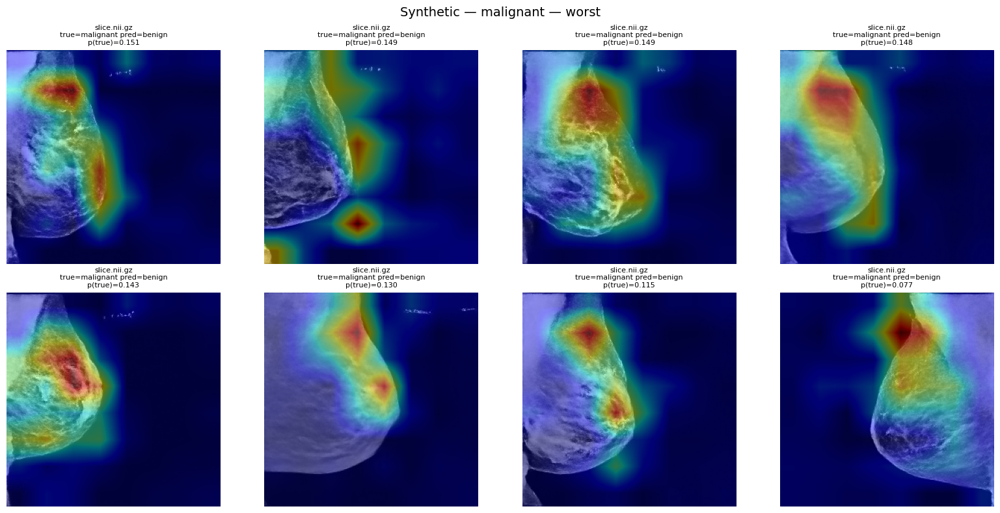

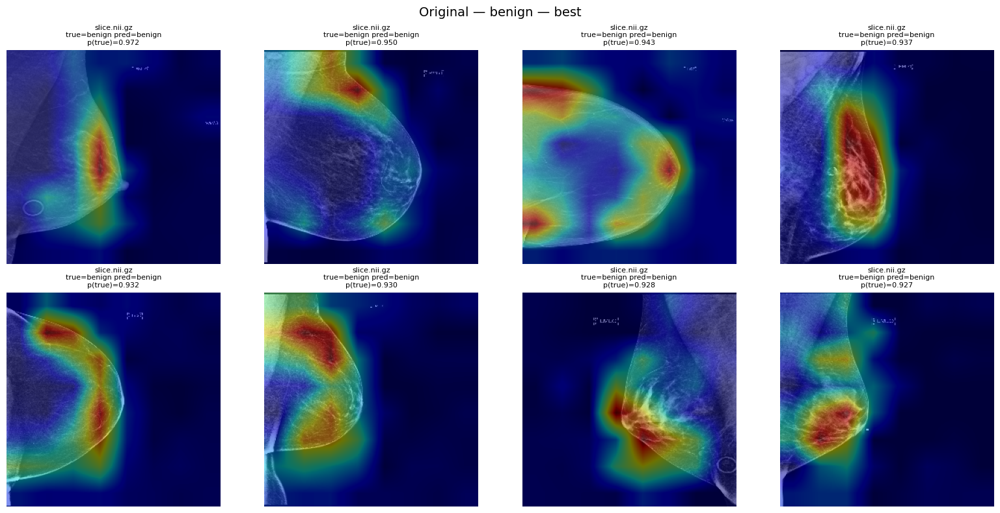

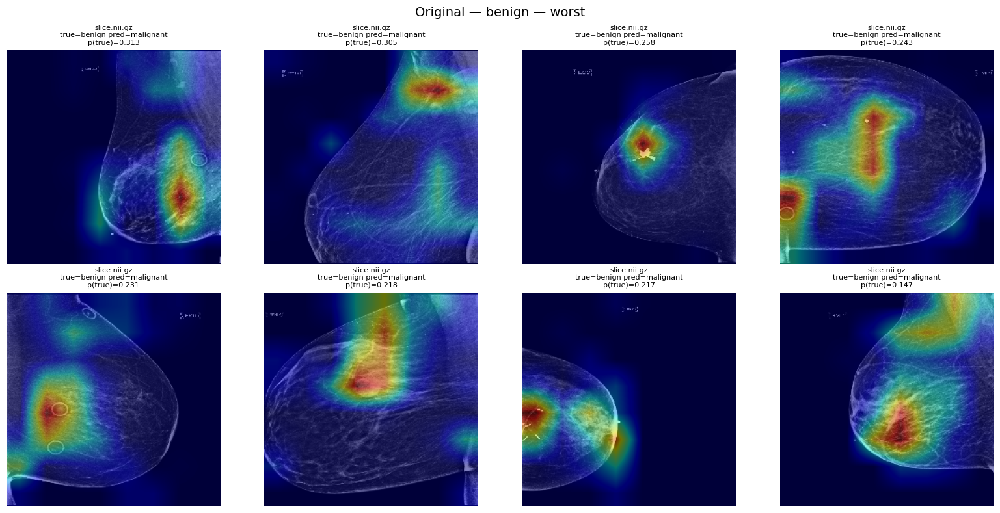

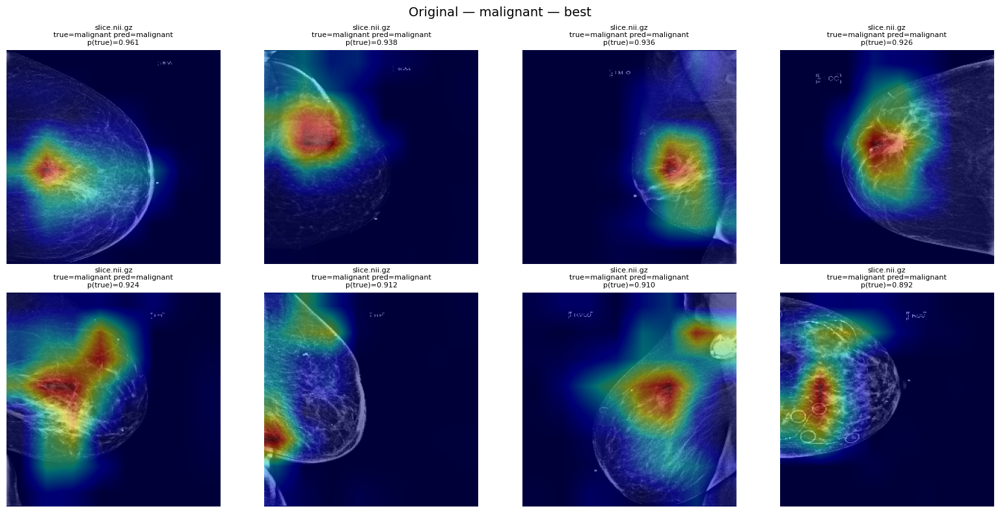

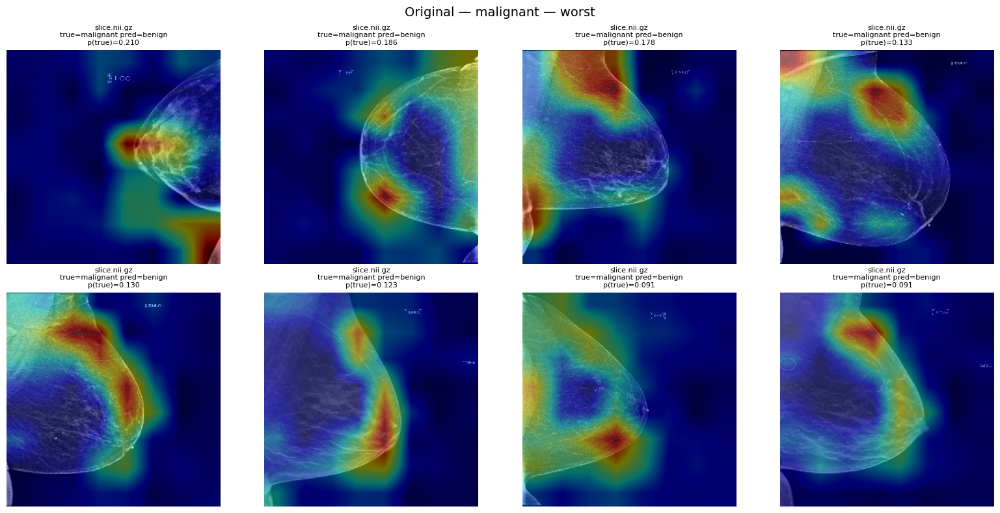

In [5]:
def add_cam(record):
    inp = oracle_norm(record["x"].unsqueeze(0).to(DEVICE)).float()
    targets = [ClassifierOutputTarget(record["pred_id"])]
    grayscale_cam = cam(input_tensor=inp, targets=targets)[0]
    out = dict(record)
    out["cam_mask"] = grayscale_cam
    out["overlay"] = make_overlay(record["img01"], grayscale_cam)
    return out

def top_bottom_by_group(source_name, class_name, top_k=8, bottom_k=8):
    group = [
        r for r in scored
        if r["source"] == source_name and r["true_label"] == class_name
    ]
    group = sorted(group, key=lambda r: r["true_prob"], reverse=True)
    best = [add_cam(r) for r in group[:top_k]]
    worst = [add_cam(r) for r in group[-bottom_k:]]
    return best, worst

for source_name in ["synthetic", "original"]:
    for cls_name in CATEGORIES:
        best, worst = top_bottom_by_group(source_name, cls_name, TOP_K, BOTTOM_K)
        show_grid(best, f"{source_name.title()} — {cls_name} — best")
        show_grid(worst, f"{source_name.title()} — {cls_name} — worst")

In [12]:
results = {}

for source_name in ["synthetic", "original"]:
    for cls_name in CATEGORIES:
        best, worst = top_bottom_by_group(source_name, cls_name, TOP_K, BOTTOM_K)
        results[(source_name, cls_name)] = {
            "best": best,
            "worst": worst
        }

In [21]:
def view_sample(record):
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    axes[0].imshow(record["img01"], cmap="gray")
    axes[0].set_title("Input")
    axes[0].axis("off")

    axes[1].imshow(record["overlay"])
    axes[1].set_title("Grad-CAM")
    axes[1].axis("off")

    fig.suptitle(
        f"{record['source']} | {record['path'].name}\n"
        f"true={record['true_label']} pred={record['pred_label']} "
        f"| p(true)={record['true_prob']:.3f} p(pred)={record['pred_prob']:.3f}",
        fontsize=10,
    )
    plt.tight_layout()
    plt.show()


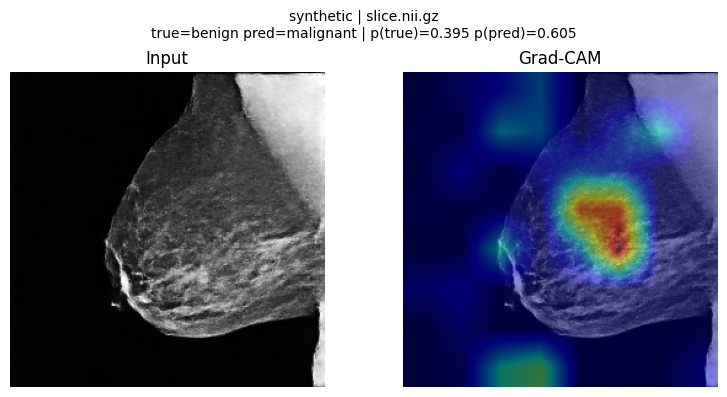

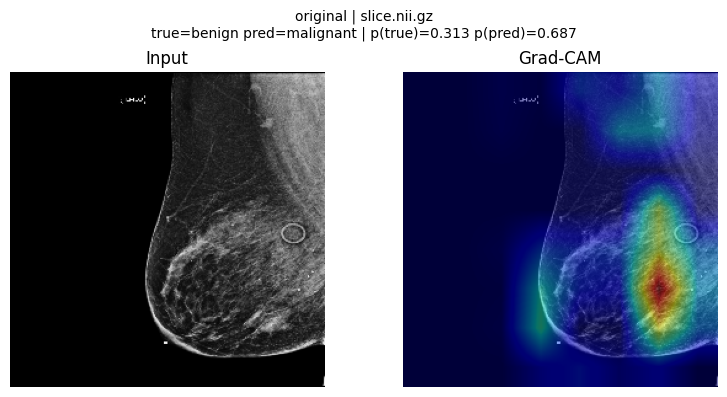

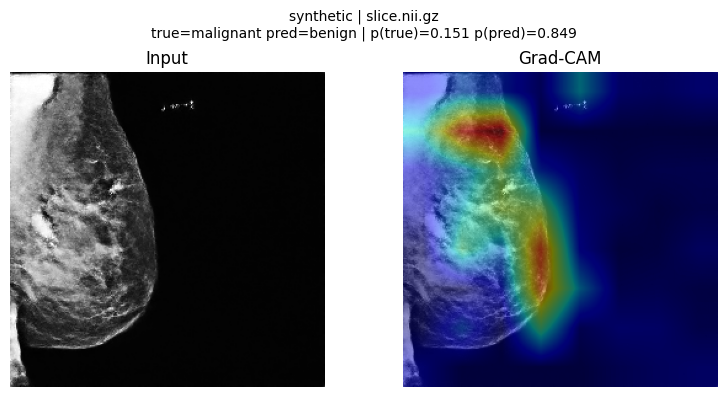

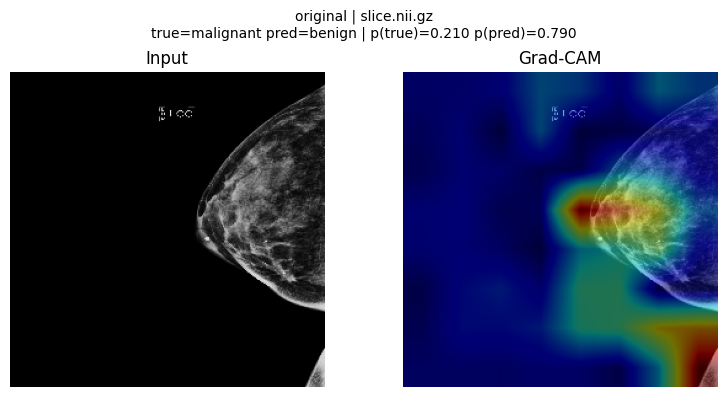

In [19]:
view_sample(results[("synthetic", "benign")]["worst"][0])
view_sample(results[("original", "benign")]["worst"][0])
view_sample(results[("synthetic", "malignant")]["worst"][0])
view_sample(results[("original", "malignant")]["worst"][0])

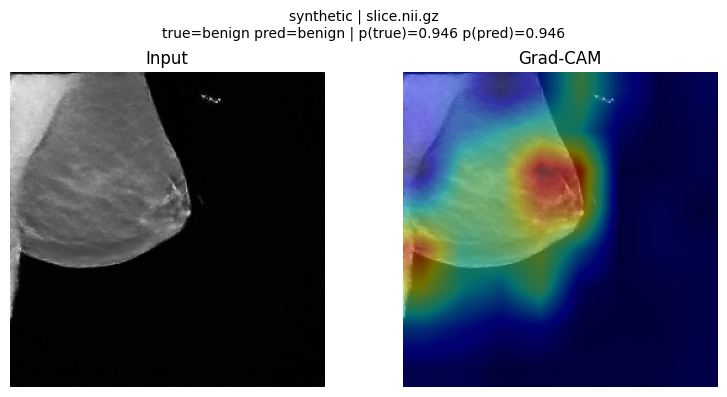

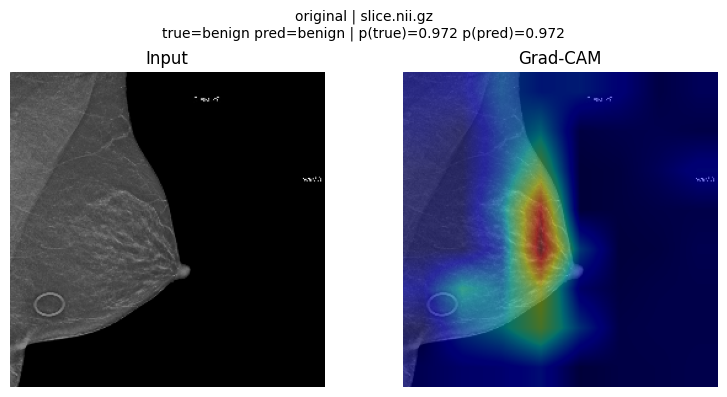

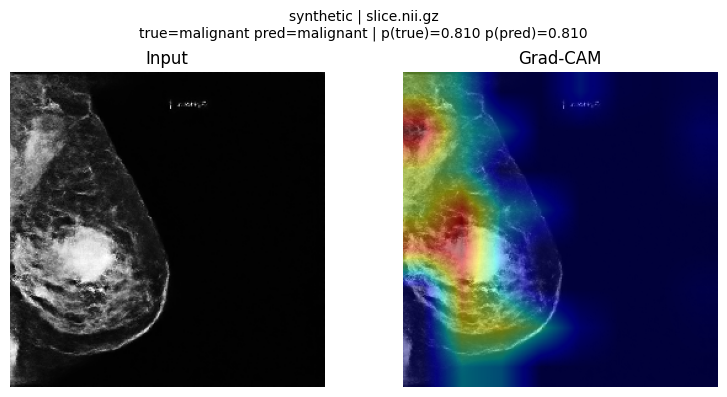

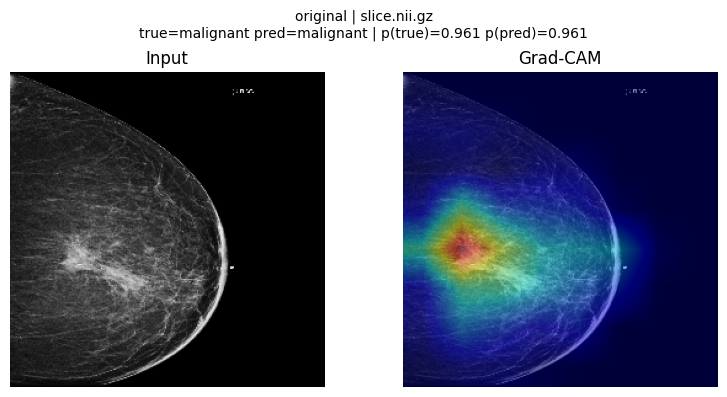

In [20]:
view_sample(results[("synthetic", "benign")]["best"][0])
view_sample(results[("original", "benign")]["best"][0])
view_sample(results[("synthetic", "malignant")]["best"][0])
view_sample(results[("original", "malignant")]["best"][0])

Saved to: ./gradcam_comparison_1.pdf


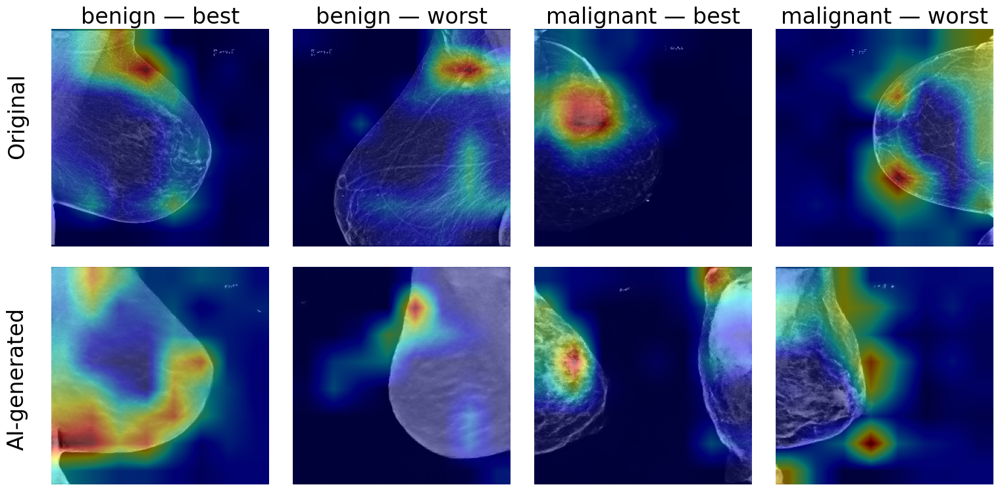

In [33]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 24,          # base font (paper-like)
    "axes.titlesize": 24,     # subplot titles
    "axes.labelsize": 24,
    "xtick.labelsize": 24,
    "ytick.labelsize": 24,
})

sample_idx = 1

row_specs = ["original", "synthetic"]

col_specs = [
    ("benign", "best"),
    ("benign", "worst"),
    ("malignant", "best"),
    ("malignant", "worst"),
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, source_name in enumerate(row_specs):
    for j, (cls_name, quality) in enumerate(col_specs):
        ax = axes[i, j]

        key = (source_name, cls_name)
        if key not in results or len(results[key][quality]) == 0:
            ax.axis("off")
            continue

        group = results[key][quality]
        rec = group[min(sample_idx, len(group) - 1)]

        ax.imshow(rec["overlay"])
        ax.axis("off")

        if i == 0:
            ax.set_title(f"{cls_name} — {quality}")

# ---- Add row labels (cleaner than set_ylabel) ----
if i == 0:
    ax.set_title(f"{cls_name} — {quality}")  # no need for fontsize now

fig.text(0.04, 0.75, "Original", va='center', rotation=90)
fig.text(0.04, 0.25, "AI-generated", va='center', rotation=90)

plt.tight_layout(rect=[0.06, 0, 1, 1])  # leave space for labels
out_path = f"./gradcam_comparison_{sample_idx}.pdf"
fig.savefig(out_path, bbox_inches="tight")
print("Saved to:", out_path)
plt.show()